In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import binom

# Load and inspect the data
df = pd.read_csv(r'E1_NASDAQ100_mid2019_2021.csv')

df.info()
print('\n')
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           653 non-null    object 
 1   Closing Price  653 non-null    float64
dtypes: float64(1), object(1)
memory usage: 20.4+ KB


Date             645
Closing Price    645
dtype: int64


In [ ]:
# Remove empty rows and convert the date column
df1 = df.dropna().copy()
df1['Date'] = pd.to_datetime(df1['Date'], dayfirst=True)

# Keep observations in chronological order
df1 = df1.sort_values('Date').reset_index(drop=True)

# Daily log return
df1['Return'] = np.log(df1['Closing Price'] / df1['Closing Price'].shift(1))

# Daily volatility estimated from the latest 21 returns
df1['Vol'] = df1['Return'].rolling(21).std()

# VaR Backtesting

In [ ]:
# Forward 10-day log return
df1['Return_10D'] = np.log(
    df1['Closing Price'].shift(-10) / df1['Closing Price']
)

# Convert daily volatility to a 10-day horizon
df1['Vol_10D'] = df1['Vol'] * np.sqrt(10)

In [ ]:
# 99% normal VaR, with the mean return ignored
df1['VaR_10D'] = -norm.ppf(0.99) * df1['Vol_10D']

**Method**: Daily log returns are first calculated from the closing prices. A rolling 21-day standard deviation is then used as the daily volatility estimate. The volatility is scaled to a 10-day horizon using the square-root-of-time rule. The 99% VaR is compared with the realised forward 10-day log return, and a breach is recorded when the realised return falls below the VaR threshold.

# (a) Report the count and percentage of VaR breaches.

In [ ]:
# A breach occurs when the realised 10-day return falls below VaR
df1['Breach'] = df1['Return_10D'] < df1['VaR_10D']

# Only rows with both VaR and forward return can be tested
valid = df1['VaR_10D'].notna() & df1['Return_10D'].notna()

T = valid.sum()
Num_breach = df1.loc[valid, 'Breach'].sum()

print(f"Number of VaR breaches: {Num_breach}")
print(f"Percentage of VaR breaches: {Num_breach / T:.2%}")

Number of VaR breaches: 19
Percentage of VaR breaches: 3.05%


### Result

The rolling SD model produced 19 VaR breaches out of 622 valid observations,
corresponding to a breach rate of 3.05%.

The traffic-light thresholds are Green for up to 11 breaches, Yellow for
12--17 breaches, and Red for more than 17 breaches. Therefore the observed
19 breaches fall in the Red zone.

# (b) Present a plot which identifies the breaches visually (with crosses).

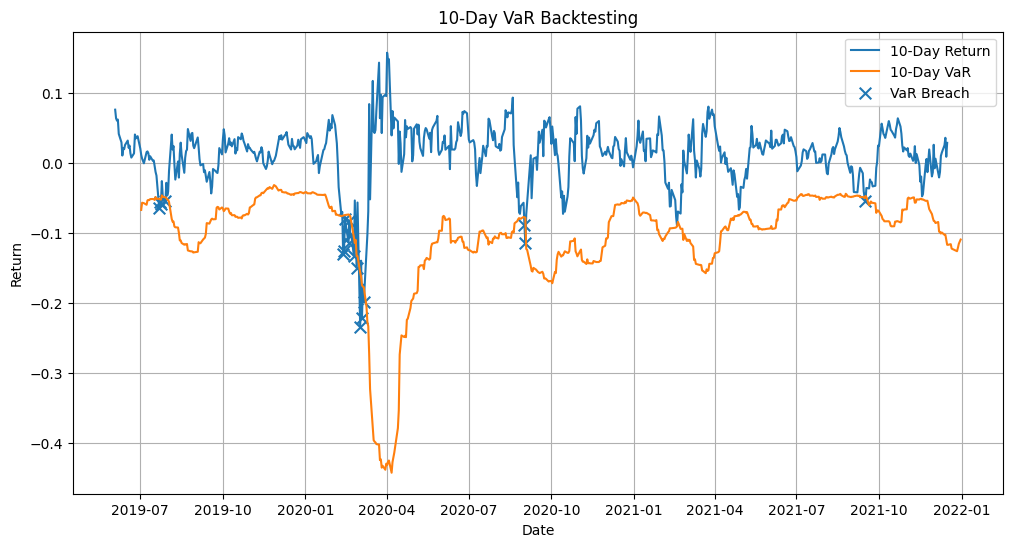

In [ ]:
plt.figure(figsize=(12, 6))

# Realised 10-day returns
plt.plot(df1['Date'], df1['Return_10D'], label='10-Day Return')

# 99% VaR
plt.plot(df1['Date'], df1['VaR_10D'], label='10-Day VaR')

# Mark breaches with crosses
breach = df1['Breach']

plt.scatter(
    df1.loc[breach, 'Date'],
    df1.loc[breach, 'Return_10D'],
    marker='x',
    s=70,
    label='VaR Breach'
)

plt.xlabel('Date')
plt.ylabel('Return')
plt.title('10-Day VaR Backtesting')
plt.legend()
plt.grid(True)
plt.show()

# (c) Report traffic-light ranges for breaches: Green / Yellow / Red.

In [ ]:
# Binomial traffic-light thresholds
q_G = int(binom.ppf(0.95, T, 0.01))
q_Y = int(binom.ppf(0.9999, T, 0.01))

print(f"Green traffic light range: 0 < b <= {q_G}")
print(f"Yellow traffic light range: {q_G} < b <= {q_Y}")
print(f"Red traffic light range: b > {q_Y}")

Green traffic light range: 0 < b <= 11
Yellow traffic light range: 11 < b <= 17
Red traffic light range: b > 17


# EWMA Volatility Forecast and VaR

### Method

The EWMA model updates the variance recursively using the previous variance
forecast and the most recent squared return,

$$
\sigma^2_{t+1|t}
=
\lambda\sigma^2_{t|t-1}
+
(1-\lambda)r_t^2.
$$

Here, $\lambda=0.72$. Therefore the latest squared return receives a
weight of $1-\lambda=0.28$. The initial variance is taken from the
variance of the available return series. After obtaining the daily EWMA
volatility, it is scaled to a 10-day horizon using the square-root-of-time
rule and converted to 99\% VaR.

In [ ]:
lam = 0.72

# EWMA is updated in variance form, so store sigma^2 first
df1['Var_EWMA'] = np.nan

# Initialise the recursion using the variance of the return series
first = df1['Return'].first_valid_index()
df1.loc[first, 'Var_EWMA'] = df1['Return'].var()

# Each new variance forecast uses the previous forecast
# and the most recently observed squared return
for i in range(first + 1, len(df1)):
    df1.loc[i, 'Var_EWMA'] = (
        lam * df1.loc[i - 1, 'Var_EWMA']
        + (1 - lam) * df1.loc[i - 1, 'Return']**2
    )

# Convert the variance forecast back to daily volatility
df1['Vol_EWMA'] = np.sqrt(df1['Var_EWMA'])

# Scale daily volatility to the 10-day VaR horizon
df1['Vol_EWMA_10D'] = np.sqrt(10) * df1['Vol_EWMA']

In [ ]:
# 99% normal VaR threshold, assuming zero mean return
df1['VaR_EWMA_10D'] = -norm.ppf(0.99)*df1['Vol_EWMA_10D']

# (a) Report the count and percentage of VaR breaches, here for this EWMA method.

In [ ]:
# A breach occurs when the realised 10-day return falls below EWMA VaR
df1['Breach_EWMA'] = (df1['Return_10D'] < df1['VaR_EWMA_10D'])

# Use only dates for which both the VaR forecast and forward return exist
valid = (
    df1['VaR_EWMA_10D'].notna()
    & df1['Return_10D'].notna()
)

T = valid.sum()
Num_breach = df1.loc[valid, 'Breach_EWMA'].sum()

print(f"Number of VaR breaches: {Num_breach}")
print(f"Percentage of VaR breaches: {Num_breach / T:.2%}")

Number of VaR breaches: 30
Percentage of VaR breaches: 4.67%


### Result

The EWMA model produced 30 VaR breaches, corresponding to approximately
4.67% of the valid backtesting observations. This is above the nominal
1% breach probability of a 99% VaR model.

Compared with the rolling-standard-deviation model, EWMA produced more
breaches in this sample. This does not mean that EWMA is less adaptive:
adaptivity describes how quickly the volatility estimate responds to new
information, while the breach rate measures how well the resulting VaR
threshold was calibrated to the realised returns.

# (b) Present a plot which identifies the breaches visually.

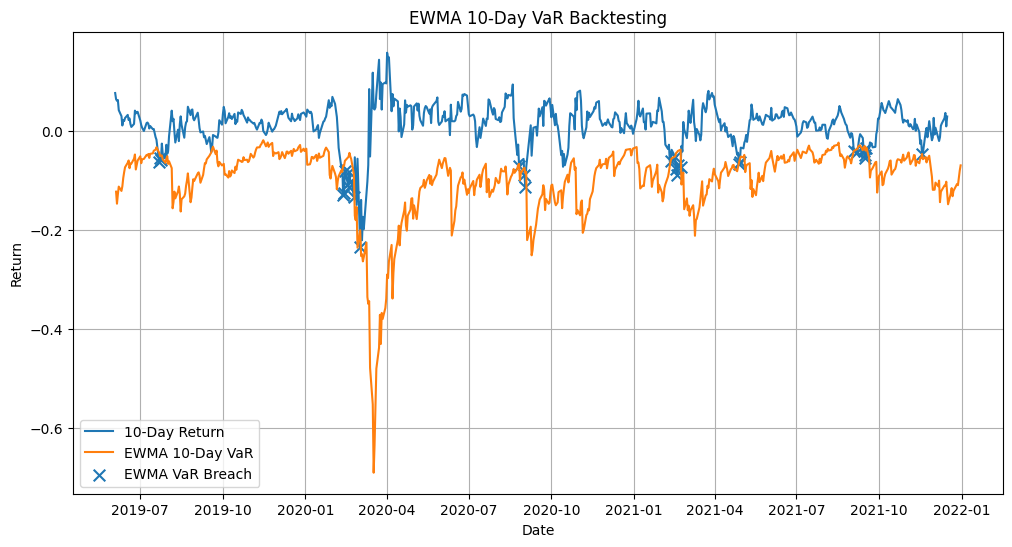

In [ ]:
plt.figure(figsize=(12, 6))

# Compare realised forward returns with the EWMA VaR threshold
plt.plot(
    df1['Date'],
    df1['Return_10D'],
    label='10-Day Return'
)

plt.plot(
    df1['Date'],
    df1['VaR_EWMA_10D'],
    label='EWMA 10-Day VaR'
)

# Mark dates where the realised return breached VaR
breach = df1['Breach_EWMA']

plt.scatter(
    df1.loc[breach, 'Date'],
    df1.loc[breach, 'Return_10D'],
    marker='x',
    s=70,
    label='EWMA VaR Breach'
)

plt.xlabel('Date')
plt.ylabel('Return')
plt.title('EWMA 10-Day VaR Backtesting')
plt.legend()
plt.grid(True)
plt.show()

# (c) Among the three approaches studied (Rolling SD, EWMA, HistSim) which exhibits cases of best and worst adaptivity to volatility?

### Adaptivity comparison

EWMA has the best adaptivity because recent returns have larger weights and
older observations gradually decay.

Rolling SD also reacts to a new shock immediately, but every return inside
the 21-day window has the same weight. The shock keeps affecting the estimate
until it leaves the window.

Historical Simulation generally has the slowest response because it uses a
historical window with equal weights. Its VaR can stay unchanged until an
important tail observation enters or leaves the window.

Therefore, EWMA is the most responsive, Rolling SD is intermediate, and
Historical Simulation can be the least responsive.